# SpecMatch: Exploratory Data Analysis & Metadata Feasibility Study

**Project:** SpecMatch: Constraint-Aware Semantic Retrieval for E-Commerce Product Search  
**Dataset:** Wayfair ANNotation Dataset (WANDS)  
**Notebook:** `01_dataset_exploration.ipynb`  
**Objective:** Inspect raw WANDS product, query, and label data to evaluate metadata structure and feasibility for constraint-aware semantic search.

---

## 1. Setup & Environment Configuration
Configure CPU-first execution, load core libraries, and set visual styling.

In [1]:
import os
import sys
import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set display and style defaults
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 150)
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100

# Determine project root dynamically
curr_dir = os.path.abspath(os.getcwd())
if os.path.exists(os.path.join(curr_dir, 'data', 'raw')):
    data_dir = os.path.join(curr_dir, 'data', 'raw')
elif os.path.exists(os.path.join(curr_dir, '..', 'data', 'raw')):
    data_dir = os.path.abspath(os.path.join(curr_dir, '..', 'data', 'raw'))
else:
    data_dir = os.path.abspath(os.path.join(curr_dir, 'SpecMatch', 'data', 'raw'))

print(f"Using raw data directory: {data_dir}")

Using raw data directory: C:\Users\singh\OneDrive\Desktop\NLP\SpecMatch\data\raw


## 2. Load Raw WANDS Tables
Load `product.csv`, `query.csv`, and `label.csv`. WANDS files are tab-delimited (`\t`).

In [2]:
product_df = pd.read_csv(os.path.join(data_dir, 'product.csv'), sep='\t')
query_df = pd.read_csv(os.path.join(data_dir, 'query.csv'), sep='\t')
label_df = pd.read_csv(os.path.join(data_dir, 'label.csv'), sep='\t')

print("=== Dataset Dimensions ===")
print(f"Products: {product_df.shape[0]:,} rows, {product_df.shape[1]} columns")
print(f"Queries:  {query_df.shape[0]:,} rows, {query_df.shape[1]} columns")
print(f"Labels:   {label_df.shape[0]:,} rows, {label_df.shape[1]} columns")

=== Dataset Dimensions ===
Products: 42,994 rows, 9 columns
Queries:  480 rows, 3 columns
Labels:   233,448 rows, 4 columns


## 3. Schema & Data Quality Verification
Check columns, data types, missing value percentages, and key uniqueness.

In [3]:
def summarize_table(df, name, id_col):
    summary = pd.DataFrame({
        'Data Type': df.dtypes,
        'Missing Values': df.isnull().sum(),
        'Missing %': (df.isnull().sum() / len(df) * 100).round(2)
    })
    n_dups = df[id_col].duplicated().sum()
    print(f"\n--- {name} Table (Primary Key: '{id_col}', Duplicate IDs: {n_dups}) ---")
    return summary

print(summarize_table(product_df, 'Product', 'product_id'))
print(summarize_table(query_df, 'Query', 'query_id'))
print(summarize_table(label_df, 'Label', 'id'))


--- Product Table (Primary Key: 'product_id', Duplicate IDs: 0) ---
                    Data Type  Missing Values  Missing %
product_id              int64               0       0.00
product_name           object               0       0.00
product_class          object            2852       6.63
category hierarchy     object            1556       3.62
product_description    object            6008      13.97
product_features       object               0       0.00
rating_count          float64            9452      21.98
average_rating        float64            9452      21.98
review_count          float64            9452      21.98

--- Query Table (Primary Key: 'query_id', Duplicate IDs: 0) ---
            Data Type  Missing Values  Missing %
query_id        int64               0       0.00
query          object               0       0.00
query_class    object               6       1.25

--- Label Table (Primary Key: 'id', Duplicate IDs: 0) ---
           Data Type  Missing Values  Mis

## 4. Relevance Label Distribution
Inspect the distribution of human relevance judgements across `Exact`, `Partial`, and `Irrelevant`.

,Count,Percentage (%)
label,,
Partial,146633,62.81
Irrelevant,61201,26.22
Exact,25614,10.97


C:\Users\singh\AppData\Local\Temp\ipykernel_14332\3491990789.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_counts.index, y=label_counts.values, palette=colors)


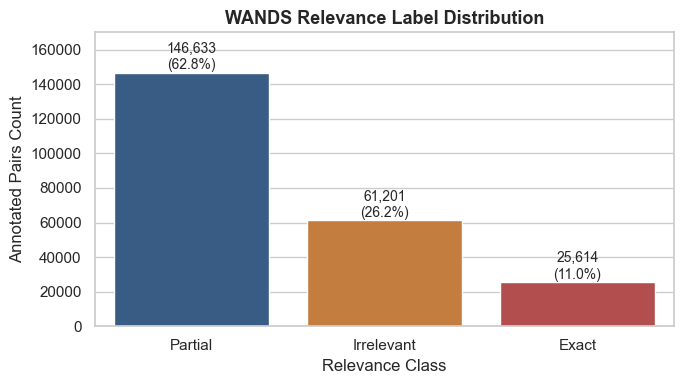

In [4]:
label_counts = label_df['label'].value_counts()
label_pcts = (label_df['label'].value_counts(normalize=True) * 100).round(2)
label_summary = pd.DataFrame({'Count': label_counts, 'Percentage (%)': label_pcts})
display(label_summary)

plt.figure(figsize=(7, 4))
colors = ['#2b5c8f', '#d97b29', '#c43d3d']
sns.barplot(x=label_counts.index, y=label_counts.values, palette=colors)
plt.title('WANDS Relevance Label Distribution', fontsize=13, fontweight='bold')
plt.xlabel('Relevance Class')
plt.ylabel('Annotated Pairs Count')
for i, v in enumerate(label_counts.values):
    plt.text(i, v + 2000, f"{v:,}\n({v/len(label_df)*100:.1f}%)", ha='center', fontsize=10)
plt.ylim(0, 170000)
plt.tight_layout()
plt.show()

## 5. Query Structure & Characteristics
Analyze query length (in words and characters), query taxonomies, and judgements per query.

Query Length Statistics:


,word_count,char_count
count,480.00,480.00
mean,3.38,20.98
std,1.50,9.21
min,1.00,3.00
25%,2.00,14.00
50%,3.00,20.00
75%,4.00,25.00
max,10.00,67.00


C:\Users\singh\AppData\Local\Temp\ipykernel_14332\2676247007.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_classes.index, x=top_classes.values, palette='Blues_r', ax=axes[1])


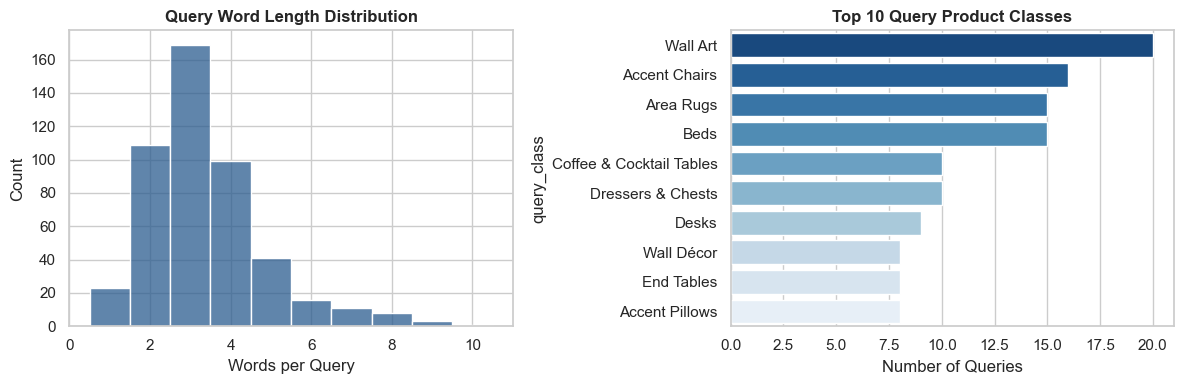

In [5]:
query_df['word_count'] = query_df['query'].astype(str).str.split().apply(len)
query_df['char_count'] = query_df['query'].astype(str).str.len()

print("Query Length Statistics:")
display(query_df[['word_count', 'char_count']].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(query_df['word_count'], discrete=True, color='#2b5c8f', ax=axes[0])
axes[0].set_title('Query Word Length Distribution', fontweight='bold')
axes[0].set_xlabel('Words per Query')

top_classes = query_df['query_class'].value_counts().head(10)
sns.barplot(y=top_classes.index, x=top_classes.values, palette='Blues_r', ax=axes[1])
axes[1].set_title('Top 10 Query Product Classes', fontweight='bold')
axes[1].set_xlabel('Number of Queries')
plt.tight_layout()
plt.show()

## 6. Product Text & Feature Metadata Analysis
Inspect the structure of `product_name`, `product_description`, and especially `product_features`.

In [6]:
product_df['name_word_count'] = product_df['product_name'].astype(str).str.split().apply(len)
product_df['desc_word_count'] = product_df['product_description'].dropna().astype(str).str.split().apply(len)

print(f"Product Name Word Count: mean={product_df['name_word_count'].mean():.2f}, max={product_df['name_word_count'].max()}")
print(f"Product Desc Word Count: mean={product_df['desc_word_count'].mean():.2f}, max={product_df['desc_word_count'].max()}")

# Sample raw features
sample_feature_str = product_df['product_features'].iloc[0]
print("\nSample parsed features from product 0:")
for pair in sample_feature_str.split('|')[:8]:
    print(f"  {pair.strip()}")

Product Name Word Count: mean=6.75, max=49
Product Desc Word Count: mean=83.02, max=791.0

Sample parsed features from product 0:
  overallwidth-sidetoside:64.7
  dsprimaryproductstyle : modern
  countryoforigin-additionaldetails : made in viet nam
  headboardtype : slat
  headboardheight-toptobedframe:25.35
  weightcapacity:500
  estimatedtimetosetup:120
  overalllength-headtotoe:77.9


## 7. Deep Dive: Constraint Attribute Availability (Colour, Material, Size, Brand)
Examine whether `product_features` provides sufficient coverage for constraint-aware retrieval.

In [7]:
# Parse all key-value pairs across the 42,994 products
feature_key_counts = Counter()
for feats in product_df['product_features'].dropna():
    for item in feats.split('|'):
        if ':' in item:
            k = item.split(':', 1)[0].strip().lower()
            feature_key_counts[k] += 1

print(f"Total unique feature keys identified: {len(feature_key_counts):,}")

# Quantify coverage for core constraint families
color_keys = {k: v for k, v in feature_key_counts.items() if 'color' in k or 'finish' in k}
material_keys = {k: v for k, v in feature_key_counts.items() if any(m in k for m in ['material', 'woodspecies', 'fabric'])}
size_keys = {k: v for k, v in feature_key_counts.items() if any(s in k for s in ['size', 'width', 'height', 'depth', 'capacity', 'dimension'])}

def top_keys_table(d, family_name):
    top = sorted(d.items(), key=lambda x: -x[1])[:6]
    return pd.DataFrame([{'Constraint Family': family_name, 'Feature Key': k, 'Catalog Occurrences': v, '% of Catalog': round(v/len(product_df)*100, 1)} for k, v in top])

constraint_overview = pd.concat([
    top_keys_table(color_keys, 'Colour'),
    top_keys_table(material_keys, 'Material'),
    top_keys_table(size_keys, 'Size / Dimension')
], ignore_index=True)

display(constraint_overview)

Total unique feature keys identified: 7,962


,Constraint Family,Feature Key,Catalog Occurrences,% of Catalog
0,Colour,color,26295,61.2
1,Colour,basecolor,8145,18.9
2,Colour,finish,7719,18.0
3,Colour,upholsterycolor,7306,17.0
4,Colour,topcolor,6536,15.2
5,Colour,glossfinish,5702,13.3
6,Material,primarymaterial,10860,25.3
7,Material,framematerial,10396,24.2
8,Material,material,9010,21.0
9,Material,upholsterymaterial,7247,16.9


## 8. Query Constraint Prevalence
Scan user search queries to identify explicit lexical constraints.

In [8]:
common_colors = {'black', 'white', 'grey', 'gray', 'blue', 'red', 'green', 'yellow', 'brown', 'pink', 'gold', 'silver', 'navy', 'beige', 'orange', 'purple', 'teal', 'turquoise', 'ivory', 'bronze'}
common_materials = {'wood', 'wooden', 'metal', 'leather', 'velvet', 'glass', 'cotton', 'linen', 'steel', 'brass', 'rattan', 'ceramic', 'plastic', 'marble', 'stone', 'iron', 'fabric', 'wool', 'acrylic'}
common_sizes = {'small', 'large', 'mini', 'tall', 'short', 'twin', 'queen', 'king', 'full', 'long', 'wide', 'compact', 'narrow', 'big', 'oversized', 'extra large', 'xxl', 'xl', '7 qt', '6.5 qt', 'round', 'square'}

def extract_matches(q_text, vocab):
    words = set(re.findall(r'\b[a-z0-9.]+\b', q_text.lower()))
    return words.intersection(vocab)

query_df['has_color'] = query_df['query'].apply(lambda q: bool(extract_matches(q, common_colors)))
query_df['has_material'] = query_df['query'].apply(lambda q: bool(extract_matches(q, common_materials)))
query_df['has_size'] = query_df['query'].apply(lambda q: bool(extract_matches(q, common_sizes)))
query_df['has_any_constraint'] = query_df['has_color'] | query_df['has_material'] | query_df['has_size']

constraint_stats = pd.DataFrame({
    'Constraint Type': ['Colour', 'Material', 'Size / Dimension', 'Any Constraint'],
    'Query Count': [
        query_df['has_color'].sum(),
        query_df['has_material'].sum(),
        query_df['has_size'].sum(),
        query_df['has_any_constraint'].sum()
    ],
    'Percentage (%)': [
        round(query_df['has_color'].sum() / len(query_df) * 100, 2),
        round(query_df['has_material'].sum() / len(query_df) * 100, 2),
        round(query_df['has_size'].sum() / len(query_df) * 100, 2),
        round(query_df['has_any_constraint'].sum() / len(query_df) * 100, 2)
    ]
})
display(constraint_stats)

print("Sample Constraint-Rich Queries:")
display(query_df[query_df['has_any_constraint']][['query_id', 'query', 'query_class']].head(10))

,Constraint Type,Query Count,Percentage (%)
0,Colour,45,9.38
1,Material,35,7.29
2,Size / Dimension,37,7.71
3,Any Constraint,107,22.29


Sample Constraint-Rich Queries:


,query_id,query,query_class
3,3,turquoise pillows,Accent Pillows
6,6,acrylic clear chair,Dining Chairs
10,10,king poster bed,Beds
12,12,large spoon and fork wall decor,Wall Décor
15,15,black 5 drawer dresser by guilford,Dressers & Chests
22,22,light and navy blue decorative pillow,Accent Pillows
23,23,stoneford end tables white and wood,End Tables
24,24,wood coffee table set by storage,Living Room Table Sets
26,26,leather chairs,Accent Chairs
31,31,burnt orange curtains,Curtains & Drapes


## 9. Relational Integrity & Judgement Pool Analysis
Verify relationships and examine query evaluation pools.

In [9]:
p_ids = set(product_df['product_id'])
q_ids = set(query_df['query_id'])
lbl_p_ids = set(label_df['product_id'])
lbl_q_ids = set(label_df['query_id'])

print(f"Foreign Key Violations: Products={len(lbl_p_ids - p_ids)}, Queries={len(lbl_q_ids - q_ids)}")
print(f"Products without any judgements: {len(p_ids - lbl_p_ids)}")

# Check duplicate pairs in label_df
dup_pairs = label_df[label_df.duplicated(subset=['query_id', 'product_id'], keep=False)]
print(f"Duplicate (query_id, product_id) rows: {len(dup_pairs)} ({label_df.duplicated(subset=['query_id', 'product_id']).sum()} duplicate entries)")

pool_sizes = label_df.groupby('query_id').size()
exact_counts = label_df[label_df['label'] == 'Exact'].groupby('query_id').size()
zero_exact = len(q_ids - set(exact_counts.index))

print(f"Judged pool size per query: min={pool_sizes.min()}, median={pool_sizes.median():.0f}, max={pool_sizes.max()}")
print(f"Queries with 0 Exact judgements: {zero_exact} (must be handled during Recall/MRR evaluation)")

Foreign Key Violations: Products=0, Queries=0
Products without any judgements: 8
Duplicate (query_id, product_id) rows: 3042 (1575 duplicate entries)
Judged pool size per query: min=1, median=216, max=4329
Queries with 0 Exact judgements: 101 (must be handled during Recall/MRR evaluation)


## 10. Conclusion & Research Safeguards Summary

1. **Feasibility:** The WANDS dataset is **fully suitable** for SpecMatch. Feature richness in `product_features` compensates for missing descriptions.
2. **Constraint Relevance:** Over **22% of queries** carry explicit lexical constraints (colour, material, size), matching structured attributes in the product catalog.
3. **Research Safeguards:**
   - Never impute or discard missing values silently.
   - Do not treat unjudged products as irrelevant.
   - Maintain separation between WANDS relevance judgements and SpecMatch constraint extraction annotations.
   - Account for the 101 queries with zero Exact labels when computing exact retrieval metrics.